In [65]:
import numpy as np 
from pathlib import Path 
from load_file import load_file
from ffreq import ffreq

file_path = Path(r"C:\Users\arni-experiment\Documents\K.Boykin\SDR_PROJECT\rtl-sdr-64bit-20260906\nfm_10sec.bin")

samples = load_file(file_path)

print("Number of complex samples:", len(samples))
print("Recording duration:", len(samples) / 2048000, "seconds")
print(samples.shape)


offsets = ffreq(
    samples, 
    fs=2_048_000,
    fr=1_000,
    dt=0.1,
    sq=0.1
)

print("Number of detected frequency bins:", len(offsets))
print("Detected frequency offsets (Hz):")
print(offsets)


Number of complex samples: 20480000
Recording duration: 10.0 seconds
(20480000,)
Number of detected frequency bins: 1865
Detected frequency offsets (Hz):
[-1024000. -1020000. -1019000. ...  1011000.  1017000.  1021000.]


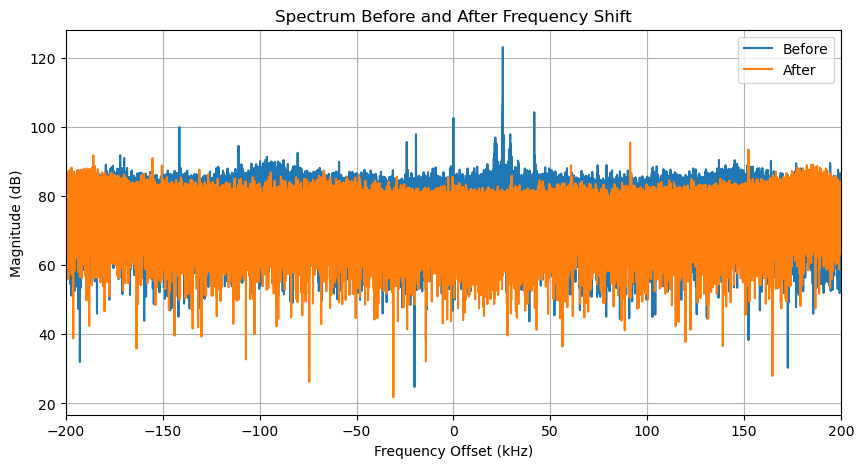

In [66]:
import matplotlib.pyplot as plt 

# The original RF waveform was sampled at 2.048 MHz ; we only need a few KHz to represent each channel 
# Demodulation corresponds to multiplying by a complex exponential 


fs = 2_048_000  # sampling freq 
dt = 1 / fs # sampling time 
t = np.arange(1, len(samples) + 1) * dt # time of each of the data samples 

# samples is the RF data loaded above and dm is the demodulated data 
dm = samples * np.exp(
    -1j * 2 * np.pi * (-996000) * t
)

#--------------------------------------------------

N = 2**18  # 262,144 samples for FFT

# BEFORE SHIFT
X = np.fft.fftshift(np.fft.fft(samples[:N]))

# AFTER SHIFT
DM = np.fft.fftshift(np.fft.fft(dm[:N]))

freq = np.fft.fftshift(
    np.fft.fftfreq(N, d=1/fs)
)

plt.figure(figsize=(10, 5))

plt.plot(
    freq / 1000,
    20 * np.log10(np.abs(X) + 1e-12),
    label="Before"
)

plt.plot(
    freq / 1000,
    20 * np.log10(np.abs(DM) + 1e-12),
    label="After"
)

plt.xlim(-200, 200)
plt.xlabel("Frequency Offset (kHz)")
plt.ylabel("Magnitude (dB)")
plt.title("Spectrum Before and After Frequency Shift")
plt.legend()
plt.grid()

plt.show()

Original IQ samples: 20480000
After first decimation: 2560000
After second decimation: 320000
Final sample rate: 32000.0 samples/sec


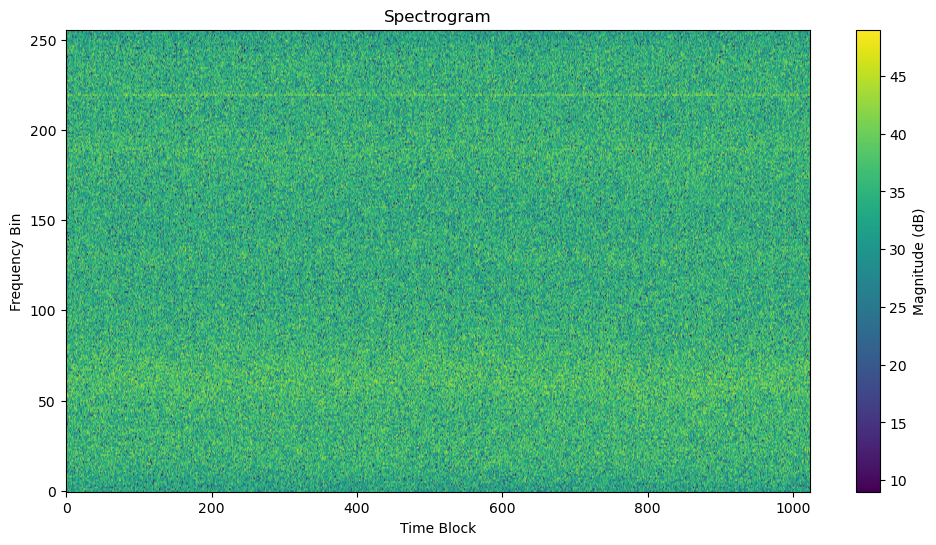

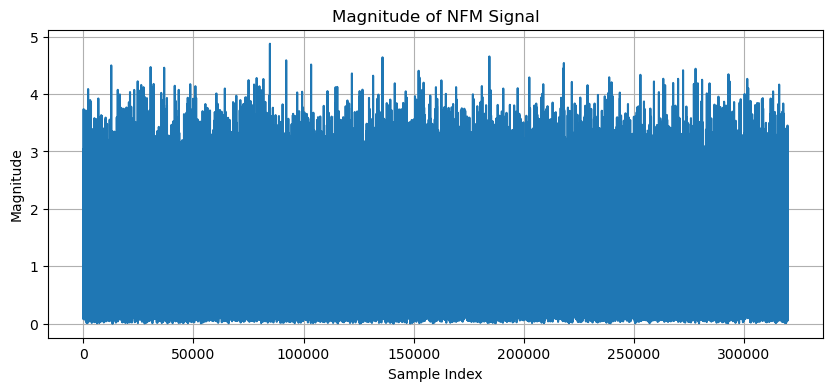

In [67]:
# NFM Processing:
# The NOAA signal was recorded at 2.048 MSPS with a center frequency
# of 162.500 MHz. After locating the NFM signal, the complex IQ signal
# is decimated by a total factor of 64 in two stages of 8, reducing
# the sample rate from 2.048 MSPS to 32 kSPS before NFM demodulation.
# The recovered message is then normalized for audio playback.

# "fir" argument says to use a finite impluse response (FIR) filter for the lowpass filter prior to decimation.
# Default is to use a Chebychev infinite impulse (IIR) filter, which is more computationally efficent 
# But has non-linear phase

# The FIR filter is a little slower to compute, but the linear phase response will be important whe decoding digital signals 

from scipy.signal import decimate 
from msg import msg 
from IPython.display import Audio 


# Original sample rate 
fs = 2_048_000


### DECIMATION ###

# First decimation by 8 / Reduces IQ sample rate 
dmd = decimate(dm, 8, ftype="fir")  # 2.048 MSPS to 256 kSPS

# Second decimation by 8 
dfm = decimate(dmd, 8, ftype="fir") # 256 kSPS to 32 kSPS

#Total decimation factor 8x8=64
# Final sample rate 
fs_dfm = fs / 64

print("Original IQ samples:", len(dm))
print("After first decimation:", len(dmd))
print("After second decimation:", len(dfm))
print("Final sample rate:", fs_dfm, "samples/sec")


### SPECTROGRAM ###

ds = msg(dmd, 1, 256, 1024)


### MAGNATIUDE OF SIGNAL ###

plt.figure(figsize=(10, 4))

plt.plot(np.abs(dfm))

plt.xlabel("Sample Index")
plt.ylabel("Magnitude")
plt.title("Magnitude of NFM Signal")

plt.grid()
plt.show()

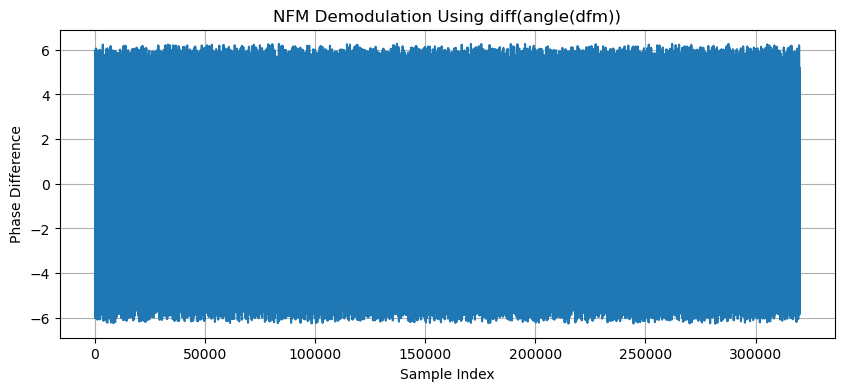

In [68]:
### INITIAL NFM DEMODULATION METHOD  ### METHOD 1 

# Take the phase angle of dfm and calculate the difference between
# consecutive samples. This attempts to recover the FM message from
# changes in phase, but phase wrapping between -pi and +pi can
# introduce large artificial jumps in the recovered signal.

ddfm_diff = np.diff(np.angle(dfm))

plt.figure(figsize=(10, 4))
plt.plot(ddfm_diff)
plt.xlabel("Sample Index")
plt.ylabel("Phase Difference")
plt.title("NFM Demodulation Using diff(angle(dfm))")
plt.grid()
plt.show()

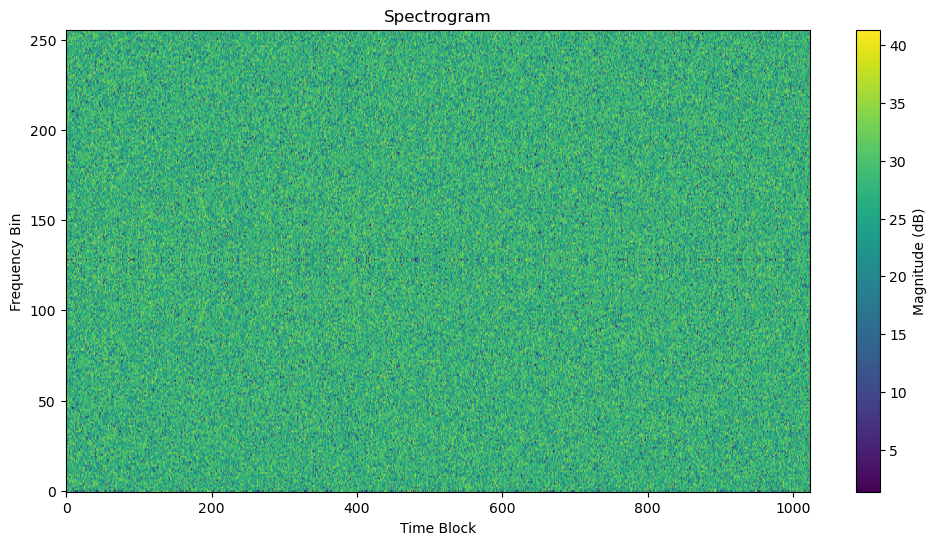

Audio sample rate: 32000.0 samples/sec


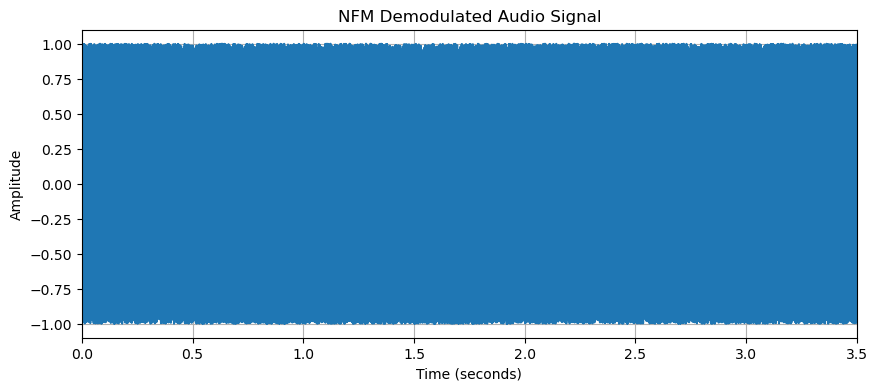

In [69]:
### IMPROVED NFM DEMODULATION METHOD ###  METHOD 2 

# Multiply each complex sample by the conjugate of the previous
# sample. The angle of the resulting product gives the phase
# difference between consecutive samples.
#
# Since instantaneous frequency is related to the rate of change
# of phase, these phase differences recover the NFM message while
# avoiding the phase-wrapping problem of directly subtracting angles.

ddfm = np.angle(
    np.conj(dfm[:-1]) * dfm[1:]
)

# Sprectrogram of demodualted audio 

ds_audio = msg(ddfm, 1, 256, 1024)

# Normalize Audio
ddfm = ddfm / np.max(np.abs(ddfm))

print("Audio sample rate:", fs_dfm, "samples/sec") #32000 

#Plays audio 
display(Audio(ddfm, rate=int(fs_dfm)))


#Display final plot 
t_audio = np.arange(len(ddfm)) / fs_dfm

plt.figure(figsize=(10, 4))
plt.plot(t_audio, ddfm)

# since recording is 10 secs long - display only the first 3.5secs to examone the waveform more closely 
plt.xlim(0, 3.5) 
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("NFM Demodulated Audio Signal")
plt.grid()

plt.show()